## Predicting-mortality-of-icu-patients-the-physionet-computing-in-cardiology-challenge-2012-1.0.0
### author--Yuyao Lei
### netid--yl1216

## AI-use statement
I used ChatGPT as supplementary aids during the development and documentation of this project in the following ways:
- Code Development and Debugging
  - Assisted in drafting and reviewing Python code for data preprocessing, feature construction, aligning predictors, and checking data consistency.
  - Helped identify potential coding errors, resolve implementation issues, and improve the organization and reproducibility of the analysis workflow.
- Statistical Modeling
  - Provided guidance on implementing and understanding LASSO logistic regression in test sets.
  - Assisted with explanations of cross-validation and the use of AUROC, sensitivity, specificity to compare predictive performance.
- Evaluation and Interpretation
  - Helped organize cross-validation results and explain model performance metrics in the code.
  - Assisted in understanding discrimination plots and calibration plots, including identifying limitations and potential issues that require further investigation.
- Documentation and Scientific Writing
  - Helped improve the clarity and organization of the written report.
  - Assisted in explaining methodological decisions, and drafting descriptions of the modeling procedures and results.

I reviewed
and tested all suggested code, verified the outputs independently, and
made the final decisions regarding data processing, predictors, validations,
and interpretation. All results were checked
against the assignment requirements and the data. I ensured that I understand the code and analysis presented, and I take full responsibility for all submitted work.

## Before start

Checkpoint 2 selected LASSO logistic regression after comparing LASSO, spline logistic regression, and random forest using the same five outer folds. Its reported mean cross-validation AUROC was about 0.843 (SD about 0.029); spline logistic regression was about 0.845 and random forest about 0.838. LASSO was retained because discrimination was similar while the sparse model is comparatively interpretable. The prediction window is the first 48 hours of the ICU stay. These are internal set-a estimates; set-b and set-c are held-out evaluation datasets.

**Principles:**
- Reuse the first-48-hour feature construction from Checkpoint 2.
- Use the saved pipeline and its original predictor columns.
- Do not select, tune, or refit the primary model using set-b/set-c.
- Evaluate discrimination, calibration, clinical usefulness, subgroups, interpretation, and confident errors.

The 0.20 risk threshold used below is an illustrative operating point for flagging patients for further review, not a validated clinical threshold or a treatment recommendation.

## Preprocessing
### Imports and paths

In [1]:
from pathlib import Path
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.special import logit
from sklearn.metrics import (
    roc_auc_score, roc_curve, precision_recall_curve,
    average_precision_score, brier_score_loss, confusion_matrix
)
from statsmodels.api import GLM, Logit, add_constant, families
from statsmodels.nonparametric.smoothers_lowess import lowess
from IPython.display import display

SEED = 123
N_BOOT = 1000
N_CALIBRATION_BOOT = 250
CLINICAL_THRESHOLD = 0.20

ROOT = Path.cwd()
DATA = ROOT / "test"
DATA_A = ROOT / "data"
OUT_3 = ROOT / "output"
OUT = ROOT / "output2"
OUT.mkdir(parents=True, exist_ok=True)
MODEL_PATH = OUT / "cp2_final_model.joblib"
CV_TABLE_PATH = OUT / "cp2_model_comparison.csv"

assert MODEL_PATH.exists(), f"Missing {MODEL_PATH}; run Checkpoint 2 first."
assert (DATA / "set-b").exists() and (DATA / "set-c").exists()
assert (DATA / "Outcomes-b.txt").exists() and (DATA / "Outcomes-c.txt").exists()

sns.set_theme(context="notebook", style="whitegrid")
pd.set_option("display.max_columns", 100)
print("Project root:", ROOT)
print("Output directory:", OUT_3)

C:\Users\Lei\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


Project root: D:\Rawdata\duke\707\checkpoint
Output directory: D:\Rawdata\duke\707\checkpoint\output


### Load the saved final model

In [2]:
artifact = joblib.load(MODEL_PATH)
assert isinstance(artifact, dict) and "pipeline" in artifact and "feature_columns" in artifact

final_model_name = artifact.get("model_name", "Unknown")
final_pipeline = artifact["pipeline"]
predictor_columns = list(artifact["feature_columns"])
target_name = artifact.get("target", "death")

print("Saved model:", final_model_name)
print("Original predictor count:", len(predictor_columns))
print("Pipeline steps:", list(final_pipeline.named_steps.keys()))
assert final_model_name == "LASSO", "Resolve discrepancy between saved artifact and Checkpoint 2 report."
assert hasattr(final_pipeline, "predict_proba")

Saved model: LASSO
Original predictor count: 190
Pipeline steps: ['preprocess', 'model']


C:\Users\Lei\anaconda3\Lib\site-packages\sklearn\base.py:380: InconsistentVersionWarning: Trying to unpickle estimator SimpleImputer from version 1.9.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\Lei\anaconda3\Lib\site-packages\sklearn\base.py:380: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.9.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\Lei\anaconda3\Lib\site-packages\sklearn\base.py:380: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from version 1.9.1 when using version 1.6.1. This might lead to breaking code or inva

### Build modeling tables for test sets

Checkpoint 2 uses measurements from hour 0 through hour 48. Repeated numeric measurements are summarized by mean, minimum, maximum, last observed value, and count; urine output is also summed. Age, height, gender, and ICU type are retained as stay-level variables. Outcome-related fields, RecordID, SAPS-I, SOFA, length of stay, and survival are not predictors.

In [3]:
def parse_elapsed_hours(time_series):
    parts = time_series.astype(str).str.split(":", expand=True)
    if parts.shape[1] < 2:
        raise ValueError("Unexpected Time format; expected HH:MM.")
    return (pd.to_numeric(parts[0], errors="coerce")
            + pd.to_numeric(parts[1], errors="coerce") / 60.0)


def build_features(split_name):
    split_dir = DATA / split_name
    files = sorted(split_dir.glob("*.txt"))
    assert files, f"No record .txt files in {split_dir}"
    pieces = []
    for file in files:
        temp = pd.read_csv(file)
        required = {"Time", "Parameter", "Value"}
        if not required.issubset(temp.columns):
            raise ValueError(f"{file.name} missing {required - set(temp.columns)}")
        temp["id"] = str(file.stem)
        pieces.append(temp)
    long_df = pd.concat(pieces, ignore_index=True)
    wide_df = long_df.pivot_table(
        index=["id", "Time"], columns="Parameter", values="Value", aggfunc="mean"
    ).reset_index()
    wide_df["id"] = wide_df["id"].astype(str)
    wide_df["_hours"] = parse_elapsed_hours(wide_df["Time"])
    window_df = wide_df.loc[wide_df["_hours"].between(0, 48, inclusive="both")].copy()
    if window_df.empty:
        raise ValueError(f"No 0–48 hour records for {split_name}")

    excluded = {"id", "RecordID", "Time", "_hours"}
    measured = [c for c in window_df.columns if c not in excluded]
    static_cols = [c for c in ["Age", "Gender", "Height", "ICUType"] if c in measured]
    continuous_cols = [c for c in measured if c not in static_cols]

    for col in continuous_cols:
        window_df[col] = pd.to_numeric(window_df[col], errors="coerce")
    for col in ["Age", "Height"]:
        if col in window_df:
            window_df[col] = pd.to_numeric(window_df[col], errors="coerce")

    features = window_df.groupby("id")[continuous_cols].agg(
        ["mean", "min", "max", "last", "count"]
    )
    features.columns = [f"{v}_{stat}" for v, stat in features.columns]
    if static_cols:
        features = features.join(window_df.groupby("id")[static_cols].first())
    if "Urine" in continuous_cols:
        features = features.join(
            window_df.groupby("id")["Urine"].sum(min_count=1).rename("Urine_sum")
        )
    features = features.reset_index().rename(columns={"id": "RecordID"})
    features["RecordID"] = pd.to_numeric(features["RecordID"], errors="raise").astype("int64")
    assert not features["RecordID"].duplicated().any()
    return features


def load_outcomes(split_name):
    suffix = split_name[-1]
    path = DATA / f"Outcomes-{suffix}.txt"
    out = pd.read_csv(path)
    required = {"RecordID", "SAPS-I", "SOFA", "Length_of_stay", "Survival", "In-hospital_death"}
    missing = required - set(out.columns)
    if missing:
        raise ValueError(f"{path.name} missing columns: {missing}")
    out["RecordID"] = pd.to_numeric(out["RecordID"], errors="raise").astype("int64")
    assert not out["RecordID"].duplicated().any()
    return out


def build_table(split_name):
    features = build_features(split_name)
    outcomes = load_outcomes(split_name)
    table = features.merge(
        outcomes, on="RecordID", how="left", validate="one_to_one", indicator=True
    )
    if not (table["_merge"] == "both").all():
        raise ValueError(f"Unmatched feature/outcome records in {split_name}: "
                         f"{table['_merge'].value_counts().to_dict()}")
    table = table.drop(columns="_merge")
    table["In-hospital_death"] = pd.to_numeric(table["In-hospital_death"], errors="coerce")
    table = table.loc[table["In-hospital_death"].notna()].copy()
    table["In-hospital_death"] = table["In-hospital_death"].astype(int)
    assert set(table["In-hospital_death"].unique()).issubset({0, 1})
    assert not table["RecordID"].duplicated().any()
    return table


df_b = build_table("set-b")
df_c = build_table("set-c")
print("set-b:", df_b.shape, "unique stays:", df_b["RecordID"].nunique())
print("set-c:", df_c.shape, "unique stays:", df_c["RecordID"].nunique())

set-b: (4000, 196) unique stays: 4000
set-c: (4000, 196) unique stays: 4000


### Tidy up predictors and predictions

The matrices are aligned to the exact set-a predictor columns saved in the artifact. Missing columns are added as missing values so that the saved imputer handles them; extra columns are excluded. No preprocessing is refitted.

In [4]:
# Compatibility workaround for the loaded LogisticRegression object
logistic_model = final_pipeline.named_steps["model"]
if not hasattr(logistic_model, "multi_class"):
    logistic_model.multi_class = "auto"

print("Model class:", type(logistic_model))
print("Model parameters:")
print(logistic_model.get_params())

Model class: <class 'sklearn.linear_model._logistic.LogisticRegression'>
Model parameters:
{'C': 0.1, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': 1.0, 'max_iter': 5000, 'multi_class': 'auto', 'n_jobs': None, 'penalty': 'deprecated', 'random_state': 123, 'solver': 'saga', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}


In [5]:
for attr in [
    "classes_",
    "coef_",
    "intercept_",
    "n_features_in_",
    "n_iter_",
]:
    value = getattr(logistic_model, attr, "NOT FOUND")

    if attr == "coef_" and hasattr(value, "shape"):
        print(f"{attr}: shape={value.shape}")
    else:
        print(f"{attr}: {value}")

classes_: [0 1]
coef_: shape=(1, 340)
intercept_: [-2.45631588]
n_features_in_: 340
n_iter_: [645]


In [7]:
def make_X(table):
    forbidden = {"RecordID", "death", "In-hospital_death", "Length_of_stay",
                 "Survival", "SAPS-I", "SOFA"}
    assert not (set(predictor_columns) & forbidden), (
        f"Leakage risk: forbidden columns in saved predictors: {set(predictor_columns) & forbidden}"
    )
    X = table.reindex(columns=predictor_columns).copy()
    for col in ["Gender", "ICUType"]:
        if col in X:
            X[col] = X[col].astype("category")
    for col in X.columns:
        if col not in ["Gender", "ICUType"]:
            X[col] = pd.to_numeric(X[col], errors="coerce")
    assert list(X.columns) == predictor_columns
    return X


X_b, X_c = make_X(df_b), make_X(df_c)
y_b = df_b["In-hospital_death"].astype(int).to_numpy()
y_c = df_c["In-hospital_death"].astype(int).to_numpy()
p_b = final_pipeline.predict_proba(X_b)[:, 1]
p_c = final_pipeline.predict_proba(X_c)[:, 1]

for name, y, p in [("set-b", y_b, p_b), ("set-c", y_c, p_c)]:
    assert len(y) == len(p) and np.isfinite(p).all()
    assert ((p >= 0) & (p <= 1)).all() and len(np.unique(y)) == 2
    print(f"{name}: stays={len(y)}, deaths={int(y.sum())}, survivors={int((y==0).sum())}, "
          f"death rate={y.mean():.3%}, predicted-risk range=({p.min():.3f}, {p.max():.3f})")

set-b: stays=4000, deaths=568, survivors=3432, death rate=14.200%, predicted-risk range=(0.002, 0.997)
set-c: stays=4000, deaths=585, survivors=3415, death rate=14.625%, predicted-risk range=(0.002, 0.999)


### Cohort description

This table provides the number of stays, deaths, survivors, and observed mortality for each test set.

In [8]:
cohort_table = pd.DataFrame([
    {"Dataset": name, "ICU stays": len(y), "Deaths": int(y.sum()),
     "Survivors": int((y == 0).sum()), "Mortality (%)": 100 * y.mean()}
    for name, y in [("set-b", y_b), ("set-c", y_c)]
])
display(cohort_table.style.format({"Mortality (%)": "{:.2f}"}))
cohort_table.to_csv(OUT_3 / "cp3_cohort_summary.csv", index=False)

,Dataset,ICU stays,Deaths,Survivors,Mortality (%)
0,set-b,4000,568,3432,14.20
1,set-c,4000,585,3415,14.62


The evaluation included two independent ICU cohorts, set-b and set-c, each comprising 4,000 ICU stays. In set-b, 568 patients died in the hospital, corresponding to an in-hospital mortality rate of 14.20%, while 3,432 survived. In set-c, 585 patients died and 3,415 survived, yielding a mortality rate of 14.62%. The two cohorts had similar sample sizes and mortality rates, suggesting comparable overall outcome distributions. Set-c had a slightly higher mortality rate than set-b (14.62% vs. 14.20%), a difference of 0.42 percentage points.

## Discrimination
### AUROC and bootstrap 95% CIs
AUROC measures ranking discrimination. The stratified bootstrap resamples deaths and survivors separately to preserve the observed class counts. The resulting interval describes uncertainty in the test-set estimate, not model-development variability.

,Dataset,Model / score,N evaluated,Deaths evaluated,AUROC,95% CI lower,95% CI upper
0,set-b,Final LASSO model,4000,568,0.861,0.845,0.878
1,set-b,SAPS-I,4000,568,0.660,0.635,0.684
2,set-b,SOFA,4000,568,0.657,0.634,0.680
3,set-c,Final LASSO model,4000,585,0.865,0.850,0.880
4,set-c,SAPS-I,4000,585,0.638,0.613,0.664
5,set-c,SOFA,4000,585,0.629,0.603,0.654


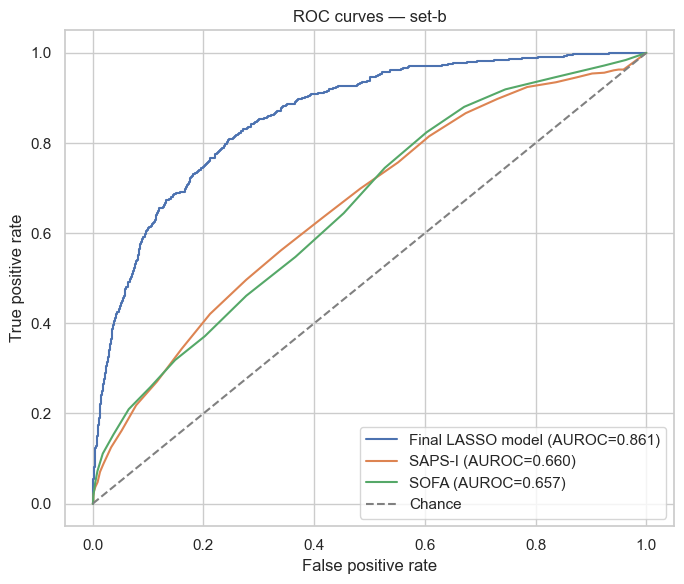

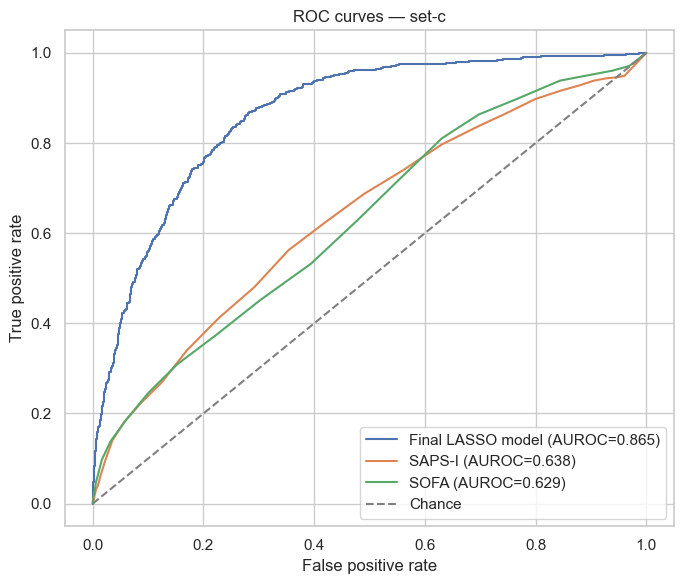

In [9]:
def auc_ci(y, score, n_boot=N_BOOT, seed=SEED):
    y, score = np.asarray(y).astype(int), np.asarray(score, dtype=float)
    valid = np.isfinite(score)
    y, score = y[valid], score[valid]
    pos, neg = np.flatnonzero(y == 1), np.flatnonzero(y == 0)
    if not len(pos) or not len(neg):
        return np.nan, np.nan, np.nan, len(y), int(y.sum())
    point = roc_auc_score(y, score)
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(n_boot):
        idx = np.r_[rng.choice(pos, len(pos), replace=True),
                    rng.choice(neg, len(neg), replace=True)]
        vals.append(roc_auc_score(y[idx], score[idx]))
    lo, hi = np.quantile(vals, [0.025, 0.975])
    return float(point), float(lo), float(hi), len(y), int(y.sum())


score_sets = {
    "set-b": {"Final LASSO model": p_b,
              "SAPS-I": pd.to_numeric(df_b["SAPS-I"], errors="coerce").to_numpy(float),
              "SOFA": pd.to_numeric(df_b["SOFA"], errors="coerce").to_numpy(float)},
    "set-c": {"Final LASSO model": p_c,
              "SAPS-I": pd.to_numeric(df_c["SAPS-I"], errors="coerce").to_numpy(float),
              "SOFA": pd.to_numeric(df_c["SOFA"], errors="coerce").to_numpy(float)}
}
y_sets = {"set-b": y_b, "set-c": y_c}

auc_rows = []
for split in ["set-b", "set-c"]:
    for model_name, scores in score_sets[split].items():
        point, lo, hi, n, deaths = auc_ci(
            y_sets[split], scores, seed=SEED + (0 if split == "set-b" else 100)
        )
        auc_rows.append({"Dataset": split, "Model / score": model_name, "N evaluated": n,
                         "Deaths evaluated": deaths, "AUROC": point,
                         "95% CI lower": lo, "95% CI upper": hi})
auc_table = pd.DataFrame(auc_rows)
display(auc_table.style.format({"AUROC": "{:.3f}", "95% CI lower": "{:.3f}",
                                "95% CI upper": "{:.3f}"}))
auc_table.to_csv(OUT_3 / "cp3_auroc_bootstrap.csv", index=False)

for split in ["set-b", "set-c"]:
    y = y_sets[split]
    plt.figure(figsize=(7, 6))
    for model_name, scores in score_sets[split].items():
        valid = np.isfinite(scores)
        if len(np.unique(y[valid])) < 2:
            continue
        fpr, tpr, _ = roc_curve(y[valid], scores[valid])
        plt.plot(fpr, tpr, label=f"{model_name} (AUROC={roc_auc_score(y[valid], scores[valid]):.3f})")
    plt.plot([0, 1], [0, 1], "--", color="grey", label="Chance")
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.title(f"ROC curves — {split}")
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUT_3 / f"cp3_roc_{split}.png", dpi=200)
    plt.show()

**Observations:**

- Consistent performance across cohorts: The final LASSO model achieved an AUROC of 0.861 (95% bootstrap CI: 0.845–0.878) in set-b and 0.865 (95% CI: 0.850–0.880) in set-c.
- Lower performance of clinical scores: In set-b, SAPS-I achieved an AUROC of 0.660 (95% CI: 0.635–0.684) and SOFA achieved 0.657 (95% CI: 0.634–0.680). In set-c, their AUROCs were 0.638 (95% CI: 0.613–0.664) and 0.629 (95% CI: 0.603–0.654), respectively.
- ROC curve patterns: In both cohorts, the LASSO ROC curve remained substantially above those of SAPS-I and SOFA across most false-positive rates. The clinical scores performed relatively similarly to each other.
- Bootstrap confidence intervals: The LASSO model's 95% confidence intervals were narrow and similar across cohorts. The clinical scores had lower AUROCs and overlapping confidence intervals with each other.

**Interpretation:**

- Strong discrimination: The LASSO model demonstrated good discrimination between patients who died in the hospital and survivors in both cohorts.
- Improved discrimination over clinical scores: The LASSO model substantially outperformed SAPS-I and SOFA in both set-b and set-c, suggesting better ranking of patients by mortality risk.
- Robustness across cohorts: The similar AUROCs and confidence intervals suggest that the LASSO model's discrimination was consistent across the two evaluation cohorts.
- Cautious statistical interpretation: The confidence intervals describe uncertainty in each AUROC estimate. Their overlap or non-overlap alone does not establish whether differences between models are statistically significant; a paired comparison would be needed for formal testing.

### Precision–Recall curve

Deaths are a minority outcome, so the PR curve shows how positive predictive value changes with sensitivity. The baseline precision equals the observed death rate.

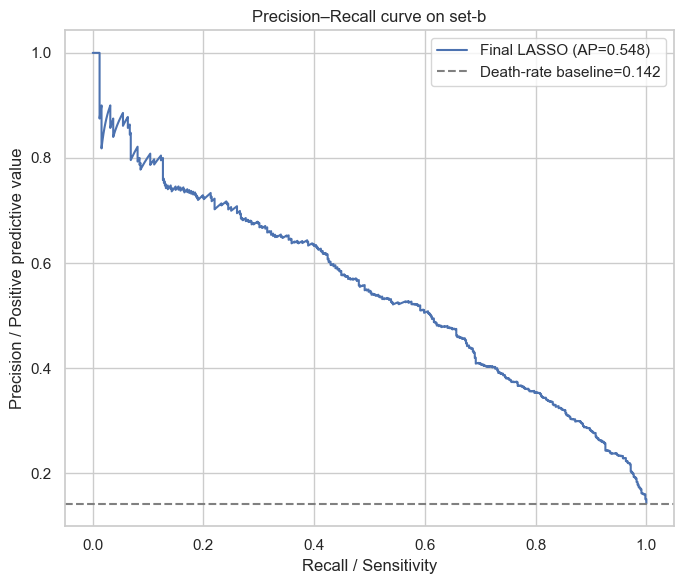

Average precision: 0.5478 | Death-rate baseline: 0.142


In [10]:
precision, recall, _ = precision_recall_curve(y_b, p_b)
ap = average_precision_score(y_b, p_b)
death_rate_b = y_b.mean()
plt.figure(figsize=(7, 6))
plt.plot(recall, precision, label=f"Final LASSO (AP={ap:.3f})")
plt.axhline(death_rate_b, linestyle="--", color="grey",
            label=f"Death-rate baseline={death_rate_b:.3f}")
plt.xlabel("Recall / Sensitivity")
plt.ylabel("Precision / Positive predictive value")
plt.title("Precision–Recall curve on set-b")
plt.legend()
plt.tight_layout()
plt.savefig(OUT_3 / "cp3_precision_recall_set_b.png", dpi=200)
plt.show()
print("Average precision:", round(ap, 4), "| Death-rate baseline:", round(death_rate_b, 4))

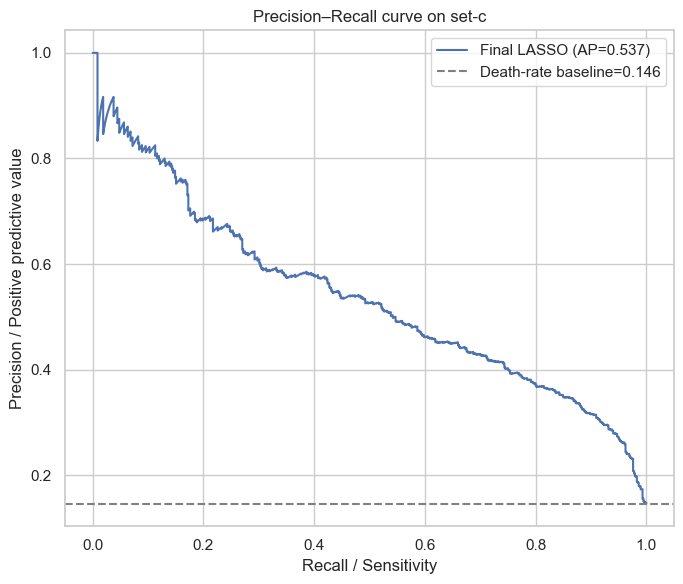

Average precision: 0.5372 | Death-rate baseline: 0.1462


In [11]:
precision_c, recall_c, _ = precision_recall_curve(y_c, p_c)
ap_c = average_precision_score(y_c, p_c)
death_rate_c = y_c.mean()
plt.figure(figsize=(7, 6))
plt.plot(recall_c, precision_c, label=f"Final LASSO (AP={ap_c:.3f})")
plt.axhline(death_rate_c, linestyle="--", color="grey",
            label=f"Death-rate baseline={death_rate_c:.3f}")
plt.xlabel("Recall / Sensitivity")
plt.ylabel("Precision / Positive predictive value")
plt.title("Precision–Recall curve on set-c")
plt.legend()
plt.tight_layout()
plt.savefig(OUT_3 / "cp3_precision_recall_set_c.png", dpi=200)
plt.show()
print("Average precision:", round(ap_c, 4), "| Death-rate baseline:", round(death_rate_c, 4))

**Observations:**

- Average precision (AP): The final LASSO model achieved an AP of 0.548 on set-b and 0.537 on set-c.
- Baseline prevalence: The mortality-rate baseline was 14.2% in set-b and 14.6% in set-c, reflecting the proportion of patients who died in each cohort.
- Precision–recall trade-off: In both cohorts, precision generally decreased as recall increased. Precision was relatively high at low recall levels but declined as the model identified more patients who died.
- Similar curves across cohorts: The precision–recall curves showed broadly similar patterns in set-b and set-c, with AP values differing by only 0.011.

**Interpretation:**

- Better than the prevalence baseline: The AP values were substantially higher than the corresponding mortality-rate baselines, indicating that the model ranked patients who died more effectively than random selection based on cohort prevalence.
- Trade-off between identifying deaths and false positives: Higher recall was associated with lower precision. Identifying a larger proportion of patients who died would therefore generally involve flagging more survivors as potential deaths.
- Consistent performance across cohorts: The similar AP values suggest that the model's precision–recall performance was reasonably consistent across the two evaluation cohorts.
- Clinical relevance: Because in-hospital death is the minority outcome in both cohorts, the precision–recall curves provide useful information about positive-case detection that complements AUROC. However, the appropriate operating threshold depends on the relative consequences of missed deaths and false alarms.

### Compare CV and external AUROC

The CV mean and SD are read from the Checkpoint 2 comparison table. Fold SD and test-set bootstrap CIs represent different uncertainty sources and should not be treated as interchangeable.

In [12]:
if CV_TABLE_PATH.exists():
    cv = pd.read_csv(CV_TABLE_PATH)
    display(cv)
    row = cv.loc[cv["model"].astype(str).str.lower().eq("lasso")]
    if len(row):
        cv_mean, cv_sd = float(row.iloc[0]["mean_AUROC"]), float(row.iloc[0]["sd_AUROC"])
    else:
        raise ValueError("LASSO row not found in cp2_model_comparison.csv")
else:
    raise FileNotFoundError("Required Checkpoint 2 comparison table is missing.")

comparison_rows = [{"Evaluation": "set-a 5-fold CV", "AUROC": cv_mean,
                    "Lower": np.nan, "Upper": np.nan, "Uncertainty": f"Fold SD={cv_sd:.3f}"}]
for split in ["set-b", "set-c"]:
    r = auc_table[(auc_table["Dataset"] == split) &
                  (auc_table["Model / score"] == "Final LASSO model")].iloc[0]
    comparison_rows.append({"Evaluation": split, "AUROC": r["AUROC"],
                            "Lower": r["95% CI lower"], "Upper": r["95% CI upper"],
                            "Uncertainty": "Bootstrap 95% CI"})
cv_external = pd.DataFrame(comparison_rows)
display(cv_external.style.format({"AUROC": "{:.3f}", "Lower": "{:.3f}", "Upper": "{:.3f}"}))
cv_external.to_csv(OUT_3 / "cp3_cv_vs_external.csv", index=False)


def auc_difference_bootstrap(y1, s1, y2, s2, n_boot=N_BOOT, seed=SEED):
    pos1, neg1 = np.flatnonzero(y1 == 1), np.flatnonzero(y1 == 0)
    pos2, neg2 = np.flatnonzero(y2 == 1), np.flatnonzero(y2 == 0)
    point = roc_auc_score(y1, s1) - roc_auc_score(y2, s2)
    rng = np.random.default_rng(seed)
    diffs = []
    for _ in range(n_boot):
        i1 = np.r_[rng.choice(pos1, len(pos1), True), rng.choice(neg1, len(neg1), True)]
        i2 = np.r_[rng.choice(pos2, len(pos2), True), rng.choice(neg2, len(neg2), True)]
        diffs.append(roc_auc_score(y1[i1], s1[i1]) - roc_auc_score(y2[i2], s2[i2]))
    lo, hi = np.quantile(diffs, [0.025, 0.975])
    return point, lo, hi

diff, diff_lo, diff_hi = auc_difference_bootstrap(y_b, p_b, y_c, p_c)
print(f"AUROC(set-b) - AUROC(set-c) = {diff:.3f}; independent bootstrap 95% CI [{diff_lo:.3f}, {diff_hi:.3f}]")
print("If this interval includes zero, the observed difference is compatible with sampling variation; it does not prove identical performance.")

,model,mean_AUROC,sd_AUROC,folds_evaluated
0,SplineLogistic,0.845060,0.024585,5
1,LASSO,0.843016,0.029152,5
2,RandomForest,0.838309,0.016885,5
3,SAPS-I,0.637870,0.029942,5
4,SOFA,0.626158,0.022246,5


,Evaluation,AUROC,Lower,Upper,Uncertainty
0,set-a 5-fold CV,0.843,nan,nan,Fold SD=0.029
1,set-b,0.861,0.845,0.878,Bootstrap 95% CI
2,set-c,0.865,0.850,0.880,Bootstrap 95% CI


AUROC(set-b) - AUROC(set-c) = -0.004; independent bootstrap 95% CI [-0.026, 0.018]
If this interval includes zero, the observed difference is compatible with sampling variation; it does not prove identical performance.


**Observations:**

- Five-fold cross-validation performance: On set-a, Spline Logistic achieved the highest mean AUROC (0.845, SD = 0.025), followed closely by LASSO (0.843, SD = 0.029) and Random Forest (0.838, SD = 0.017). All three models substantially outperformed SAPS-I (0.638, SD = 0.030) and SOFA (0.626, SD = 0.022). Each model was evaluated across five folds.
- External evaluation performance: The final LASSO model achieved an AUROC of 0.861 (bootstrap 95% CI: 0.845–0.878) on set-b and 0.865 (95% CI: 0.850–0.880) on set-c.
- Comparison across evaluation settings: The LASSO AUROC was approximately 0.843 during five-fold cross-validation on set-a, compared with 0.861 on set-b and 0.865 on set-c.
- Difference between external cohorts: The observed AUROC difference, set-b minus set-c, was −0.004, with an independent-bootstrap 95% CI of −0.026 to 0.018.

**Interpretation:**

- Consistent model ranking: The three machine-learning models showed substantially better discrimination than SAPS-I and SOFA during cross-validation. Spline Logistic and LASSO had similar mean AUROCs, while Random Forest had slightly lower AUROC but the smallest fold-to-fold SD among the three.
- Promising external performance: The final LASSO model maintained high discrimination in both external evaluation cohorts, with AUROCs above 0.86.
- Similar performance across external cohorts: Because the confidence interval for the AUROC difference includes zero, the observed difference is compatible with sampling variability. This does not establish that the two AUROCs are identical.
- Cross-validation versus external evaluation: The external AUROCs were numerically higher than the cross-validation mean. However, these estimates come from different evaluation settings, so the difference alone does not establish that external performance is better or that the model generalizes more effectively.

## Calibration

Calibration assesses agreement between predicted risk and observed mortality. We report a flexible LOWESS curve with a bootstrap confidence band, calibration-in-the-large, calibration slope, Brier score, and scaled Brier score. The Hosmer–Lemeshow test is not used as the primary assessment.

Ideal intercept = 0 and slope = 1. Positive intercept indicates underprediction; negative intercept indicates overprediction. Slope below 1 suggests predictions are too extreme; above 1 suggests predictions are too timid. Interpret the metrics together with the curve and risk regions with sparse observations.

,Dataset,N,Deaths,Calibration intercept,Calibration slope,Brier score,Scaled Brier score
0,set-b,4000,568,-0.018,1.068,0.0880,0.278
1,set-c,4000,585,0.029,1.006,0.0921,0.262


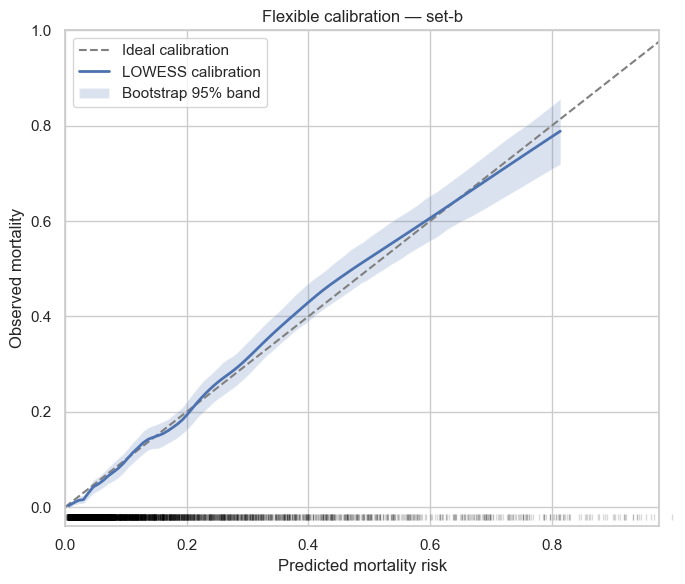

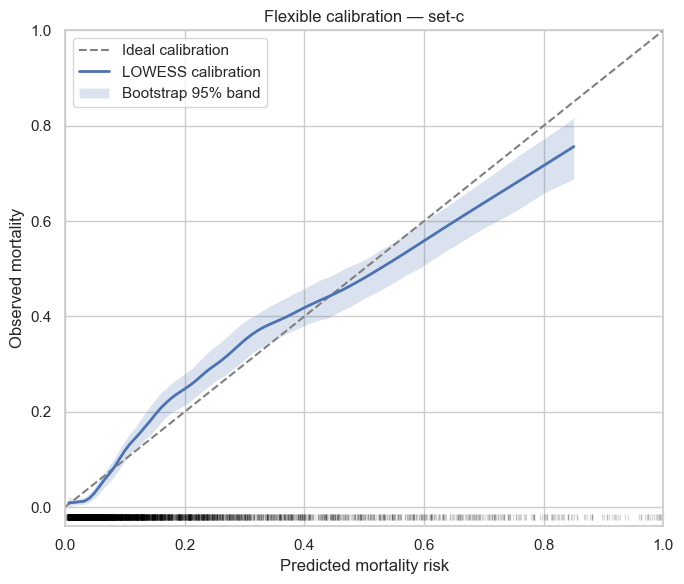

In [13]:
def safe_logit(p):
    return logit(np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6))


def cal_intercept(y, p):
    try:
        fit = GLM(np.asarray(y).astype(int), np.ones((len(y), 1)),
                  family=families.Binomial(), offset=safe_logit(p)).fit()
        return float(fit.params[0])
    except Exception:
        return np.nan


def cal_slope(y, p):
    try:
        fit = GLM(np.asarray(y).astype(int), add_constant(safe_logit(p)),
                  family=families.Binomial()).fit()
        return float(fit.params[1])
    except Exception:
        return np.nan


def brier_and_scaled(y, p):
    bs = brier_score_loss(y, p)
    reference = np.mean((np.asarray(y) - np.mean(y)) ** 2)
    return float(bs), float(1 - bs / reference) if reference > 0 else np.nan


def lowess_band(y, p, n_boot=N_CALIBRATION_BOOT, seed=SEED):
    y, p = np.asarray(y, float), np.asarray(p, float)
    grid = np.linspace(max(.001, np.quantile(p, .01)),
                       min(.999, np.quantile(p, .99)), 100)
    fit = lowess(y, p, frac=.35, it=0, return_sorted=True)
    curve = np.interp(grid, fit[:, 0], fit[:, 1])
    rng = np.random.default_rng(seed)
    boot = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        if len(np.unique(y[idx])) < 2:
            continue
        try:
            f = lowess(y[idx], p[idx], frac=.35, it=0, return_sorted=True)
            f = f[np.argsort(f[:, 0])]
            boot.append(np.interp(grid, f[:, 0], f[:, 1]))
        except Exception:
            pass
    if len(boot) >= 20:
        lo, hi = np.quantile(np.asarray(boot), [.025, .975], axis=0)
    else:
        lo, hi = np.full_like(grid, np.nan), np.full_like(grid, np.nan)
    return grid, curve, lo, hi


cal_rows = []
for split, y, p in [("set-b", y_b, p_b), ("set-c", y_c, p_c)]:
    bs, sbs = brier_and_scaled(y, p)
    cal_rows.append({"Dataset": split, "N": len(y), "Deaths": int(y.sum()),
                     "Calibration intercept": cal_intercept(y, p),
                     "Calibration slope": cal_slope(y, p),
                     "Brier score": bs, "Scaled Brier score": sbs})
cal_table = pd.DataFrame(cal_rows)
display(cal_table.style.format({"Calibration intercept": "{:.3f}",
                                "Calibration slope": "{:.3f}",
                                "Brier score": "{:.4f}", "Scaled Brier score": "{:.3f}"}))
cal_table.to_csv(OUT_3 / "cp3_calibration_metrics.csv", index=False)

for split, y, p in [("set-b", y_b, p_b), ("set-c", y_c, p_c)]:
    grid, curve, lo, hi = lowess_band(y, p, seed=SEED + (0 if split == "set-b" else 1))
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.plot([0, 1], [0, 1], "--", color="grey", label="Ideal calibration")
    ax.plot(grid, curve, label="LOWESS calibration", linewidth=2)
    if np.isfinite(lo).any():
        ax.fill_between(grid, lo, hi, alpha=.2, label="Bootstrap 95% band")
    ax.plot(p, np.full_like(p, -.02), "|", alpha=.15, markersize=5,
            clip_on=False, color="black")
    ax.set_xlim(0, min(1, max(.25, np.quantile(p, .995) * 1.1)))
    ax.set_ylim(-.04, min(1, max(.25, np.quantile(y, .99) + .15)))
    ax.set_xlabel("Predicted mortality risk")
    ax.set_ylabel("Observed mortality")
    ax.set_title(f"Flexible calibration — {split}")
    ax.legend()
    fig.tight_layout()
    fig.savefig(OUT_3 / f"cp3_calibration_{split}.png", dpi=200)
    plt.show()

**Observations:**

- Calibration intercept and slope: In set-b, the calibration intercept was −0.018 and the slope was 1.068. In set-c, the intercept was 0.029 and the slope was 1.006.
- Set-b calibration curve: The LOWESS curve generally follows the ideal calibration line. It lies slightly above the ideal line across much of the moderate predicted-risk range, particularly around predicted risks of 0.3–0.5, and slightly below it at higher risks.
- Set-c calibration curve: The LOWESS curve lies above the ideal line at lower-to-moderate predicted risks, particularly around 0.15–0.35, but falls below the ideal line at higher risks. The bootstrap 95% bands indicate uncertainty around both curves, with wider bands in some risk ranges.
- Overall prediction error: The Brier scores were 0.0880 for set-b and 0.0921 for set-c. The scaled Brier scores were 0.278 and 0.262, respectively.

**Interpretation:**

- Overall calibration: Both cohorts show reasonably good agreement between predicted and observed mortality risks, although some deviations from ideal calibration remain.
- Set-b: The intercept close to zero indicates little overall calibration-in-the-large bias. The slope slightly above 1 suggests that predicted risks may be insufficiently dispersed, with lower risks tending to be too low and higher risks too high under the usual calibration interpretation. However, the LOWESS curve shows that deviations vary across the risk range.
- Set-c: The intercept and slope are both close to their ideal values of 0 and 1, respectively, indicating good overall calibration by these summary measures. Nevertheless, the LOWESS curve reveals local miscalibration, with observed mortality exceeding predicted risk at some lower-to-moderate risks and falling below predicted risk at higher risks.
- Comparison between cohorts: Set-b has a lower Brier score and a slightly higher scaled Brier score than set-c, suggesting somewhat better overall probabilistic accuracy relative to the respective outcome prevalence baselines. These metrics do not, by themselves, establish a statistically significant difference between cohorts.

## Clinical usefulness

### DCA and threshold metrics

DCA compares net benefit across thresholds. Since SOFA is a raw score rather than a probability, its mapping to mortality risk is fitted using set-a outcomes only, then applied unchanged to the test sets. The LASSO model is not refitted. Net benefit at threshold p_t is TP/N-(FP/N){p_t/(1-p_t)}.

Again, the selected 0.20 threshold is an illustrative scenario for flagging patients for additional review, not a direct treatment decision.

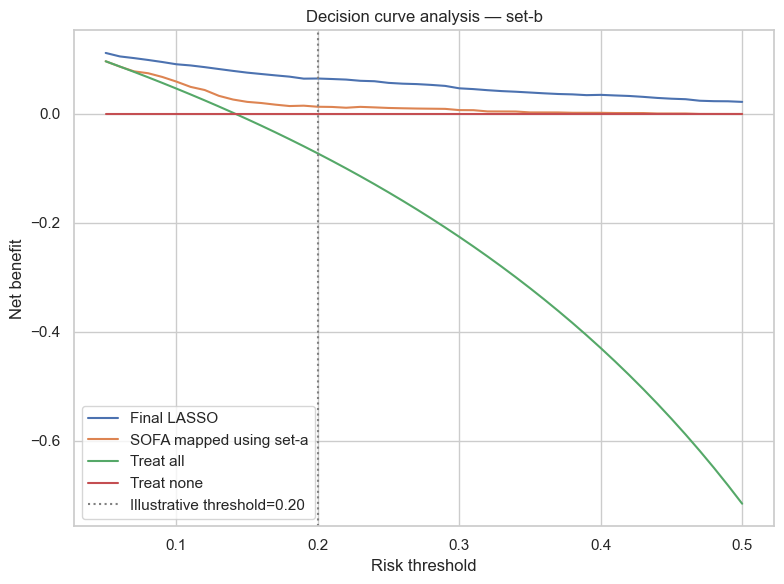

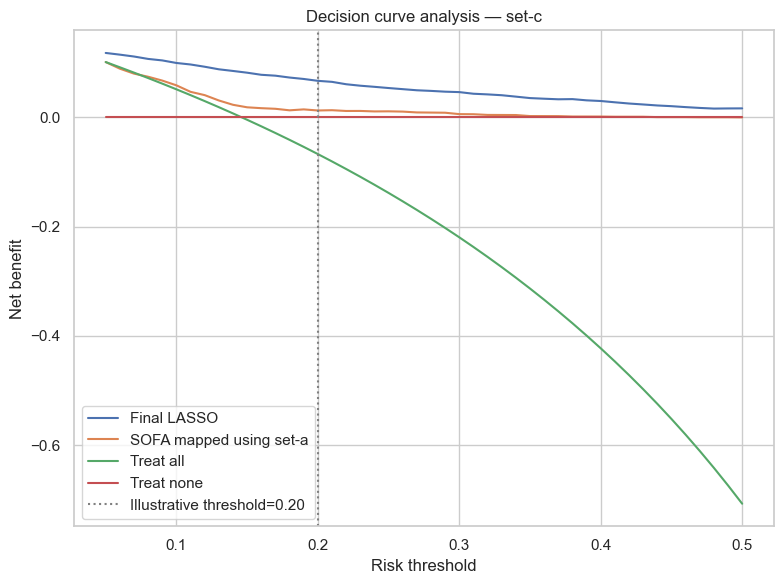

,Dataset,Threshold,N,Flagged,Flagged per 100,Sensitivity,PPV,Event 1 score,TP,FP,TN,FN
0,set-b,0.200000,4000,912,22.8,0.688,0.429,0.429,391,521,2911,177
1,set-c,0.200000,4000,909,22.7,0.677,0.436,0.436,396,513,2902,189


In [14]:
outcomes_a = pd.read_csv(DATA_A / "Outcomes-a.txt")
outcomes_a["SOFA"] = pd.to_numeric(outcomes_a["SOFA"], errors="coerce")
outcomes_a["In-hospital_death"] = pd.to_numeric(outcomes_a["In-hospital_death"], errors="coerce")
sofa_train = outcomes_a.dropna(subset=["SOFA", "In-hospital_death"]).copy()
sofa_train["In-hospital_death"] = sofa_train["In-hospital_death"].astype(int)
sofa_map = Logit(sofa_train["In-hospital_death"],
                 add_constant(sofa_train[["SOFA"]], has_constant="add")).fit(disp=False)

def sofa_risk(score):
    score = np.asarray(score, dtype=float)
    out = np.full(score.shape, np.nan)
    valid = np.isfinite(score)
    if valid.any():
        design = pd.DataFrame({"const": 1.0, "SOFA": score[valid]})
        out[valid] = sofa_map.predict(design)
    return np.clip(out, 1e-6, 1 - 1e-6)

sofa_b, sofa_c = sofa_risk(df_b["SOFA"]), sofa_risk(df_c["SOFA"])


def dca_values(y, p, thresholds):
    y, p = np.asarray(y).astype(int), np.asarray(p, dtype=float)
    rows = []
    prevalence = y.mean()
    for pt in thresholds:
        flagged = p >= pt
        tp = np.sum(flagged & (y == 1))
        fp = np.sum(flagged & (y == 0))
        nb = tp / len(y) - fp / len(y) * pt / (1 - pt)
        nb_all = prevalence - (1 - prevalence) * pt / (1 - pt)
        rows.append({"threshold": pt, "model": nb, "treat_all": nb_all, "treat_none": 0.0})
    return pd.DataFrame(rows)


thresholds = np.linspace(.05, .50, 46)
dca_rows = []
for split, y, model_p, sofa_p in [
    ("set-b", y_b, p_b, sofa_b), ("set-c", y_c, p_c, sofa_c)
]:
    model_d = dca_values(y, model_p, thresholds)
    valid = np.isfinite(sofa_p)
    sofa_d = dca_values(y[valid], sofa_p[valid], thresholds)
    for i, pt in enumerate(thresholds):
        dca_rows.append({"Dataset": split, "Threshold": pt,
                         "Final LASSO": model_d.loc[i, "model"],
                         "SOFA mapped using set-a": sofa_d.loc[i, "model"],
                         "Treat all": model_d.loc[i, "treat_all"],
                         "Treat none": 0.0})
dca_table = pd.DataFrame(dca_rows)
dca_table.to_csv(OUT_3 / "cp3_decision_curve_data.csv", index=False)

for split in ["set-b", "set-c"]:
    d = dca_table[dca_table["Dataset"] == split]
    plt.figure(figsize=(8, 6))
    for col in ["Final LASSO", "SOFA mapped using set-a", "Treat all", "Treat none"]:
        plt.plot(d["Threshold"], d[col], label=col)
    plt.axvline(CLINICAL_THRESHOLD, linestyle=":", color="grey",
                label=f"Illustrative threshold={CLINICAL_THRESHOLD:.2f}")
    plt.xlabel("Risk threshold")
    plt.ylabel("Net benefit")
    plt.title(f"Decision curve analysis — {split}")
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUT_3 / f"cp3_dca_{split}.png", dpi=200)
    plt.show()


def threshold_metrics(y, p, threshold):
    y, p = np.asarray(y).astype(int), np.asarray(p, float)
    pred = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    sens = tp / (tp + fn) if tp + fn else np.nan
    ppv = tp / (tp + fp) if tp + fp else np.nan
    return {"Threshold": threshold, "N": len(y), "Flagged": int(pred.sum()),
            "Flagged per 100": 100 * pred.mean(), "Sensitivity": sens, "PPV": ppv,
            "Event 1 score": min(sens, ppv) if np.isfinite(sens) and np.isfinite(ppv) else np.nan,
            "TP": int(tp), "FP": int(fp), "TN": int(tn), "FN": int(fn)}

threshold_table = pd.DataFrame([
    {"Dataset": "set-b", **threshold_metrics(y_b, p_b, CLINICAL_THRESHOLD)},
    {"Dataset": "set-c", **threshold_metrics(y_c, p_c, CLINICAL_THRESHOLD)}
])
display(threshold_table.style.format({"Flagged per 100": "{:.1f}", "Sensitivity": "{:.3f}",
                                      "PPV": "{:.3f}", "Event 1 score": "{:.3f}"}))
threshold_table.to_csv(OUT_3 / "cp3_threshold_metrics.csv", index=False)

**Observations:**

- set-b: The Final LASSO model (blue curve) maintains a positive net benefit across the evaluated risk thresholds (approximately 0.05–0.50). It consistently outperforms the SOFA-based strategy (orange curve) and the treat-none strategy (red line). The treat-all strategy (green curve) becomes unfavorable at relatively low thresholds and its net benefit decreases as the threshold increases.
- set-c: A similar pattern is observed. The Final LASSO model maintains a positive net benefit and outperforms the SOFA-based and treat-none strategies across the displayed threshold range. The treat-all strategy shows increasingly negative net benefit at higher thresholds.
- At the illustrative threshold of 0.20: The LASSO curve is clearly above the other strategies in both datasets. The SOFA-based strategy provides only a small positive net benefit, while treat-all has negative net benefit.

**Interpretation:**

- The DCA results suggest that the Final LASSO model may provide greater clinical decision-making value than the compared strategies across a range of risk thresholds. Its advantage is not limited to distinguishing patients who die from those who survive; it may also help support decisions about whom to flag for further assessment or intervention.
- The similar patterns in set-b and set-c suggest that the model's decision-analytic advantage is reasonably consistent across these two datasets. However, DCA alone does not establish that implementing the model would improve patient outcomes; prospective clinical evaluation would be needed.
- At a threshold of 0.20, the model identifies approximately two-thirds of deaths while flagging fewer than one-quarter of ICU stays. This suggests a potential screening role when prioritizing patients for closer monitoring or further assessment. The PPV values indicate that fewer than half of the flagged patients die in hospital. Thus, a substantial proportion of flagged patients are survivors, and additional clinical assessment would be needed before making intervention decisions. The similar metrics across set-b and set-c support consistency in the model's threshold-based performance.

## Subgroup performance in set-b

At minimum, evaluate age group, gender, and ICU type. Report stays, deaths, mortality, AUROC, and calibration-in-the-large. Age groups below are descriptive (<40, 40–64, 65+); check the data distribution and document any needed changes. Small event counts and multiple comparisons make subgroup findings exploratory.

In [15]:
sub = pd.DataFrame({
    "y": y_b, "p": p_b,
    "Age": pd.to_numeric(df_b["Age"] if "Age" in df_b else np.nan, errors="coerce"),
    "Gender": df_b["Gender"].astype("string").fillna("Unknown") if "Gender" in df_b else "Unknown",
    "ICUType": df_b["ICUType"].astype("string").fillna("Unknown") if "ICUType" in df_b else "Unknown"
})
sub["Age group"] = pd.cut(sub["Age"], [-np.inf, 39, 64, np.inf],
                          labels=["<40", "40–64", "65+"]).astype("string").fillna("Unknown")

def subgroup_rows_for(dimension, groups):
    rows = []
    tmp = pd.DataFrame({"group": groups, "y": y_b, "p": p_b})
    for level, g in tmp.groupby("group", dropna=False, observed=False):
        yy, pp = g["y"].to_numpy(int), g["p"].to_numpy(float)
        auc = roc_auc_score(yy, pp) if len(np.unique(yy)) == 2 else np.nan
        rows.append({"Dimension": dimension, "Subgroup": str(level), "Stays": len(g),
                     "Deaths": int(yy.sum()), "Mortality (%)": 100 * yy.mean(),
                     "AUROC": auc,
                     "Calibration-in-the-large": cal_intercept(yy, pp)
                         if len(np.unique(yy)) == 2 else np.nan})
    return rows

subgroup_rows = []
for dim in ["Age group", "Gender", "ICUType"]:
    subgroup_rows += subgroup_rows_for(dim, sub[dim])
subgroup_table = pd.DataFrame(subgroup_rows)
display(subgroup_table.style.format({"Mortality (%)": "{:.2f}", "AUROC": "{:.3f}",
                                     "Calibration-in-the-large": "{:.3f}"}))
subgroup_table.to_csv(OUT_3 / "cp3_subgroup_performance_set_b.csv", index=False)

,Dimension,Subgroup,Stays,Deaths,Mortality (%),AUROC,Calibration-in-the-large
0,Age group,40–64,1441,148,10.27,0.883,-0.063
1,Age group,65+,2201,391,17.76,0.838,-0.012
2,Age group,<40,358,29,8.10,0.872,0.160
3,Gender,-1.0,5,0,0.00,nan,nan
4,Gender,0.0,1742,259,14.87,0.859,-0.056
5,Gender,1.0,2253,309,13.72,0.864,0.021
6,ICUType,1.0,590,72,12.20,0.835,-0.195
7,ICUType,2.0,782,34,4.35,0.865,-0.401
8,ICUType,3.0,1436,286,19.92,0.823,0.099
9,ICUType,4.0,1192,176,14.77,0.874,-0.009


**Observations:**

- Age groups: AUROC ranges from 0.838 to 0.883. The 40–64 group has the highest AUROC (0.883), followed by patients aged <40 (0.872), while the 65+ group has the lowest AUROC (0.838). Mortality is highest among patients aged 65+ (17.76%) and lowest among those aged <40 (8.10%).
- Gender: The two main gender-coded groups show similar discrimination, with AUROCs of 0.859 and 0.864. Mortality rates are 14.87% and 13.72%, respectively. The group coded −1 contains only five stays and no deaths, so its AUROC and calibration-in-the-large are unavailable.
- ICU types: AUROC ranges from 0.823 to 0.874. ICU type 4 has the highest AUROC (0.874), followed by type 2 (0.865), type 1 (0.835), and type 3 (0.823). Mortality varies substantially, from 4.35% in type 2 to 19.92% in type 3.
- Calibration-in-the-large: Values vary across subgroups. Among the main gender-coded groups, values are −0.056 and 0.021. Across age groups, they range from −0.063 to 0.160; across ICU types, they range from −0.401 to 0.099.

**Interpretation:**

- Discrimination across age groups: The model discriminates well across all three age groups, but its AUROC is lower among patients aged 65+. This suggests that distinguishing patients who die from those who survive may be somewhat more difficult in the oldest group.
- Gender consistency: Similar AUROCs across the two main gender-coded groups suggest comparable discrimination. However, the small group coded −1 cannot support a reliable performance assessment.
- Variation across ICU types: Although AUROCs remain above 0.80 for all four ICU types, the lower value for type 3 suggests weaker discrimination in this subgroup. The large differences in mortality also indicate that baseline risk varies across ICU types.
- Calibration requires attention: The calibration-in-the-large values vary across subgroups, particularly across ICU types. If this metric is defined as mean predicted risk minus observed event rate, negative values indicate average underprediction and positive values indicate average overprediction. Under that definition, ICU type 2 (−0.401) shows substantial underprediction, whereas ICU type 3 (0.099) shows overprediction. Confirm the metric's sign convention before making these interpretations.
- Subgroup limitations: These are descriptive results. Differences in AUROC alone do not establish statistically significant performance differences or prove that the model is biased. Subgroup sample sizes, event counts, and uncertainty intervals should also be considered.

## Model interpretation

Because the selected model is LASSO logistic regression, report the fitted coefficients after preprocessing rather than SHAP for a tree ensemble. Numeric variables are standardized in the training pipeline; categorical variables are one-hot encoded. Coefficients and missingness indicators are predictive associations, not causal effects.

,Transformed feature,Coefficient,Odds ratio per transformed unit,Absolute coefficient
53,num__GCS_last,-0.8092,0.4452,0.8092
185,num__Age,0.4738,1.6060,0.4738
23,num__BUN_last,0.2666,1.3055,0.2666
150,num__Temp_mean,-0.2610,0.7703,0.2610
337,cat__ICUType_2.0,-0.2291,0.7953,0.2291
28,num__Bilirubin_last,0.2143,1.2390,0.2143
51,num__GCS_min,0.1956,1.2161,0.1956
69,num__HCT_count,-0.1690,0.8445,0.1690
54,num__GCS_count,0.1633,1.1774,0.1633
154,num__Temp_count,-0.1575,0.8542,0.1575


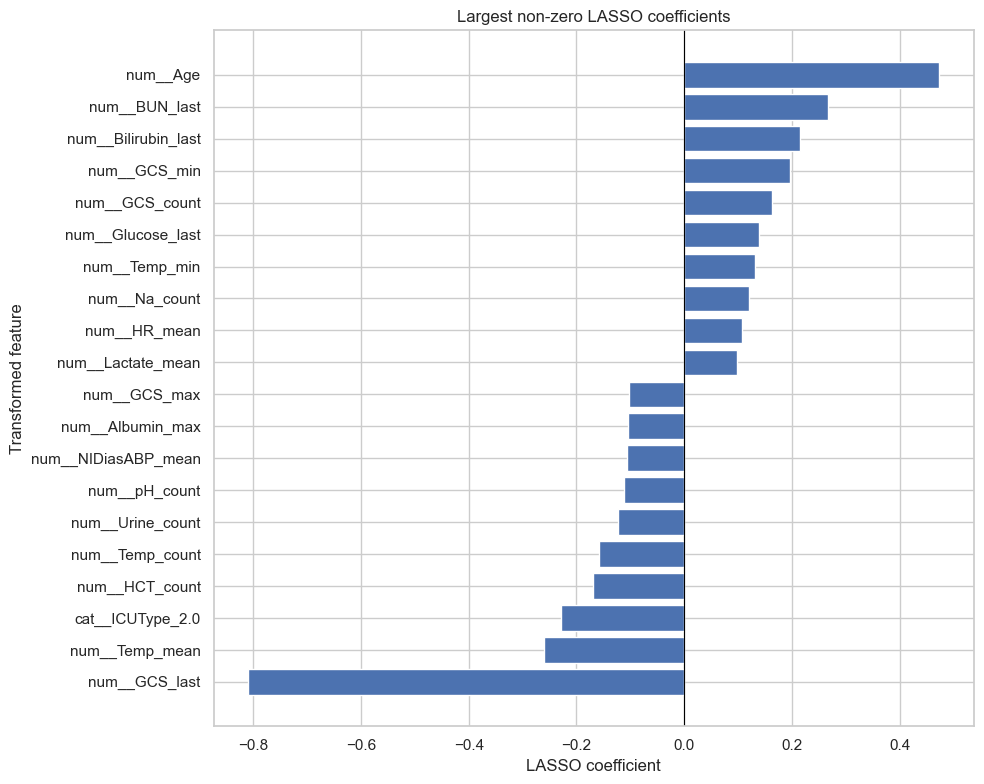

Non-zero coefficients: 125


In [16]:
preprocessor = final_pipeline.named_steps["preprocess"]
logistic_model = final_pipeline.named_steps["model"]
transformed_names = preprocessor.get_feature_names_out()
coefficients = logistic_model.coef_.ravel()
coef_table = pd.DataFrame({
    "Transformed feature": transformed_names,
    "Coefficient": coefficients,
    "Odds ratio per transformed unit": np.exp(np.clip(coefficients, -20, 20)),
    "Absolute coefficient": np.abs(coefficients)
}).sort_values("Absolute coefficient", ascending=False)
display(coef_table.head(30).round(4))
coef_table.to_csv(OUT_3 / "cp3_lasso_coefficients.csv", index=False)

nonzero = coef_table.loc[coef_table["Coefficient"] != 0].copy()
plot_coef = nonzero.head(20).sort_values("Coefficient")
plt.figure(figsize=(10, 8))
plt.barh(plot_coef["Transformed feature"], plot_coef["Coefficient"])
plt.axvline(0, color="black", linewidth=.8)
plt.xlabel("LASSO coefficient")
plt.ylabel("Transformed feature")
plt.title("Largest non-zero LASSO coefficients")
plt.tight_layout()
plt.savefig(OUT_3 / "cp3_lasso_coefficients.png", dpi=200)
plt.show()
print("Non-zero coefficients:", len(nonzero))

**Observations:**

- Coefficient distribution: The plot displays the 20 largest non-zero LASSO coefficients, including both positive and negative coefficients. The final model retains 125 non-zero coefficients.
- Largest positive coefficients: Age has the largest positive coefficient, followed by BUN_last, Bilirubin_last, GCS_min, and GCS_count. Other positive coefficients include Glucose_last, Temp_min, Na_count, HR_mean, and Lactate_mean.
- Largest negative coefficients: GCS_last has the largest negative coefficient by absolute magnitude, followed by Temp_mean and ICUType_2.0. Other negative coefficients include HCT_count, Temp_count, GCS_max, and Albumin_max.
- Variation in coefficient magnitude: The magnitudes of the displayed coefficients vary considerably, with GCS_last standing out from the other features.

**Interpretation:**

- Direction of association: Assuming the model predicts in-hospital mortality, positive coefficients indicate that higher feature values are associated with higher predicted log-odds of death, while negative coefficients indicate lower predicted log-odds, conditional on the other model features.
- Potentially important predictors: The large positive coefficient for Age suggests that age contributes substantially to mortality risk prediction. The large negative coefficient for GCS_last suggests that the last recorded Glasgow Coma Scale (GCS) value is an important predictor in the opposite direction.
- Feature selection: LASSO regularization shrinks some coefficients to zero, retaining 125 non-zero coefficients. This allows the model to use a subset of predictors while controlling model complexity.
- Important limitation: Coefficient magnitude alone does not establish causal importance or reliably rank predictive importance, especially when features have different scales or are correlated. The negative coefficients for GCS_last and GCS_min may also reflect their relationship with other GCS features in the model.
- The coefficient plot suggests that age, laboratory measurements, and GCS-related features contribute to the LASSO model's mortality predictions, with Age and GCS_last showing the largest coefficients in opposite directions. However, these coefficients represent conditional model associations, not causal effects.

## Most confident mistakes in set-b

Select approximately five survivors with the highest predicted risk and five deaths with the lowest predicted risk. For LASSO, transformed-feature contributions are computed as transformed value × fitted coefficient on the log-odds scale. These explain the model's prediction, not the clinical cause of the outcome.

In [17]:
errors = pd.DataFrame({"RecordID": df_b["RecordID"].to_numpy(),
                       "Outcome": y_b, "Predicted risk": p_b})
hi_survivors = errors[errors["Outcome"] == 0].nlargest(5, "Predicted risk").copy()
hi_survivors["Error type"] = "High predicted risk, survived"
lo_deaths = errors[errors["Outcome"] == 1].nsmallest(5, "Predicted risk").copy()
lo_deaths["Error type"] = "Low predicted risk, died"
selected_errors = pd.concat([hi_survivors, lo_deaths], ignore_index=True)

row_indices = df_b.index[df_b["RecordID"].isin(selected_errors["RecordID"])].to_list()
X_err = X_b.loc[row_indices]
ids_err = df_b.loc[row_indices, "RecordID"].to_numpy()
Z = preprocessor.transform(X_err)
if hasattr(Z, "toarray"):
    Z = Z.toarray()
Z = np.asarray(Z)
contrib = Z * coefficients.reshape(1, -1)

driver_rows = []
for i, rid in enumerate(ids_err):
    idx = np.argsort(np.abs(contrib[i]))[::-1][:5]
    driver_rows.append({
        "RecordID": int(rid),
        "Top model contributions (log-odds)": "; ".join(
            f"{transformed_names[j]} ({contrib[i, j]:+.3f})" for j in idx
        )
    })
drivers = pd.DataFrame(driver_rows)
selected_errors = selected_errors.merge(drivers, on="RecordID", how="left")
selected_errors["Review prompt"] = (
    "Review values, missingness, timing, and unobserved clinical changes; "
    "misclassification alone does not prove a data error."
)
display(selected_errors)
selected_errors.to_csv(OUT_3 / "cp3_confident_errors_set_b.csv", index=False)

,RecordID,Outcome,Predicted risk,Error type,Top model contributions (log-odds),Review prompt
0,151348,0,0.940502,"High predicted risk, survived",num__GCS_last (+2.113); num__Glucose_last (+1....,"Review values, missingness, timing, and unobse..."
1,144653,0,0.921500,"High predicted risk, survived",num__GCS_last (+2.113); num__Lactate_mean (+0....,"Review values, missingness, timing, and unobse..."
2,142993,0,0.888198,"High predicted risk, survived",num__Bilirubin_last (+1.518); num__BUN_last (+...,"Review values, missingness, timing, and unobse..."
3,148973,0,0.866704,"High predicted risk, survived",num__Bilirubin_last (+1.260); num__GCS_last (+...,"Review values, missingness, timing, and unobse..."
4,148307,0,0.824480,"High predicted risk, survived",num__GCS_last (+2.113); num__Age (+0.425); num...,"Review values, missingness, timing, and unobse..."
5,147723,1,0.010715,"Low predicted risk, died",num__Age (-1.167); num__GCS_count (+0.655); nu...,"Review values, missingness, timing, and unobse..."
6,152270,1,0.014961,"Low predicted risk, died",num__Age (-0.978); num__Weight_last (-0.571); ...,"Review values, missingness, timing, and unobse..."
7,152476,1,0.015162,"Low predicted risk, died",num__GCS_last (-0.581); num__Temp_count (-0.48...,"Review values, missingness, timing, and unobse..."
8,150189,1,0.015698,"Low predicted risk, died",num__GCS_last (-0.581); num__Temp_count (-0.24...,"Review values, missingness, timing, and unobse..."
9,143448,1,0.015924,"Low predicted risk, died",num__GCS_last (-0.581); num__Age (+0.317); cat...,"Review values, missingness, timing, and unobse..."


**Observations:**

- The table presents the 10 most confident prediction errors: five patients who survived but were assigned high mortality risks, and five patients who died but were assigned very low risks.
- Among the false positives, predicted mortality risks range from 82.4% to 94.1%. Among the false negatives, predicted risks are only 1.1%–1.6%.
- Features such as the last Glasgow Coma Scale (GCS), age, bilirubin, BUN, and laboratory measurement counts appear repeatedly among the top model contributions.
- The review prompts recommend checking feature values, missingness, measurement timing, and possible unobserved clinical factors.

**Interpretation:**

- These cases reveal errors made with high confidence, rather than merely borderline predictions. They highlight situations in which the model's risk estimates substantially disagree with observed outcomes.
- False positives may reflect clinical recovery or other factors not fully captured by the predictors, while false negatives may reflect deterioration or important risk information that the model missed. These are possible explanations, not established causes.
- Repeated contributions from GCS, age, and laboratory variables suggest that these features play an important role in individual predictions. However, their contributions should not be interpreted as causal effects, and the displayed values alone do not establish whether the underlying measurements were erroneous.
- Reviewing these cases can help identify potential data-quality issues, limitations in the predictor set, or patient subgroups for which the model may be less reliable.

The model makes a small set of highly confident errors in both directions. Reviewing these cases may help explain failure modes and guide future model improvement, but individual examples alone cannot establish the overall frequency or cause of model errors.

## Conclusions, limitations, and leakage assessment

After running the notebook, write the conclusions using the actual outputs. Address:

1. Clinical usefulness: net benefit across thresholds, workload per 100 patients, and sensitivity–PPV trade-off.
2. Limitations: single source, first-48-hour window, missingness, simplified time-varying physiology, limited event counts, and any observed external discrimination/calibration problems.
3. Leakage: post-prediction measurements, outcome-related fields, identifiers, test-set preprocessing refitting, test-set tuning, and duplicate patients across splits. Explain how the pipeline and checks prevent these risks.
4. Causal interpretation: treatment variables, measurement counts, and missingness indicators may reflect severity or care processes and must not be interpreted causally.

The held-out set-b and set-c results do not by themselves establish clinical readiness. Use in practice would require validation in the intended setting, a defensible action threshold, and an impact evaluation.

In [18]:
final_rows = []
for split, y, p in [("set-b", y_b, p_b), ("set-c", y_c, p_c)]:
    tm = threshold_metrics(y, p, CLINICAL_THRESHOLD)
    final_rows.append({
        "Dataset": split, "N": len(y), "Deaths": int(y.sum()),
        "Mortality (%)": 100 * y.mean(), "AUROC": roc_auc_score(y, p),
        "Calibration intercept": cal_intercept(y, p),
        "Calibration slope": cal_slope(y, p),
        "Brier score": brier_score_loss(y, p),
        "Threshold": CLINICAL_THRESHOLD, "Sensitivity": tm["Sensitivity"],
        "PPV": tm["PPV"], "Flagged per 100": tm["Flagged per 100"]
    })
final_summary = pd.DataFrame(final_rows)
display(final_summary.style.format({
    "Mortality (%)": "{:.2f}", "AUROC": "{:.3f}",
    "Calibration intercept": "{:.3f}", "Calibration slope": "{:.3f}",
    "Brier score": "{:.4f}", "Sensitivity": "{:.3f}",
    "PPV": "{:.3f}", "Flagged per 100": "{:.1f}"
}))
final_summary.to_csv(OUT_3 / "cp3_final_summary.csv", index=False)

print("Generated files:")
for path in sorted(OUT_3.glob("cp3_*")):
    print("-", path.name)

,Dataset,N,Deaths,Mortality (%),AUROC,Calibration intercept,Calibration slope,Brier score,Threshold,Sensitivity,PPV,Flagged per 100
0,set-b,4000,568,14.20,0.861,-0.018,1.068,0.0880,0.200000,0.688,0.429,22.8
1,set-c,4000,585,14.62,0.865,0.029,1.006,0.0921,0.200000,0.677,0.436,22.7


Generated files:
- cp3_auroc_bootstrap.csv
- cp3_calibration_metrics.csv
- cp3_calibration_set-b.png
- cp3_calibration_set-c.png
- cp3_cohort_summary.csv
- cp3_confident_errors_set_b.csv
- cp3_cv_vs_external.csv
- cp3_dca_set-b.png
- cp3_dca_set-c.png
- cp3_decision_curve_data.csv
- cp3_final_summary.csv
- cp3_lasso_coefficients.csv
- cp3_lasso_coefficients.png
- cp3_precision_recall_set_b.png
- cp3_precision_recall_set_c.png
- cp3_roc_set-b.png
- cp3_roc_set-c.png
- cp3_subgroup_performance_set_b.csv
- cp3_threshold_metrics.csv


**Observations:**

- Both external datasets contain 4,000 ICU stays, with mortality rates of 14.20% in set-b and 14.62% in set-c. The AUROC values are 0.861 and 0.865, respectively.
- At a risk threshold of 0.20, sensitivity is 0.688 in set-b and 0.677 in set-c; PPV is 0.429 and 0.436, respectively. The model flags approximately 23 patients per 100 in both datasets.

**Interpretation:**

- The similar AUROC values suggest that the LASSO model maintains good discrimination across both datasets. Calibration intercepts (−0.018 and 0.029) and slopes (1.068 and 1.006) are close to their ideal values of 0 and 1, respectively, indicating generally good calibration.
- The similar threshold-based results suggest consistent classification behavior across the two datasets. However, the model misses approximately one-third of deaths at this threshold, and fewer than half of flagged patients die in hospital. The Brier scores (0.0880 and 0.0921) provide additional information about probabilistic prediction error.

## Summary

Checkpoint 3 evaluates the LASSO mortality prediction model beyond its original training dataset by examining external discrimination, calibration, clinical utility, subgroup performance, model coefficients, and high-confidence errors. Overall, the model demonstrates consistent discrimination and generally good calibration on set-b and set-c. However, threshold-dependent false negatives, imperfect positive predictive value, and subgroup differences remain important limitations. Further validation and error review are needed before drawing conclusions about clinical deployment.